# 2. Differentiating steels by category

Before asking what furnace or air cooling does, the steel must be placed in the right category: a plain
low-carbon steel, a eutectoid steel and a Ni-Cr-Mo steel respond to the same cooling in completely different
ways, and stainless or tool steels are outside the ferrite-pearlite scope altogether.

A classifier is trained on heats simulated inside the published composition ranges of 547 grades and
evaluated on **unseen grades** (grade-grouped cross-validation) and on **real measured heats**.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s02_classifier_cv.csv")

,model,cv_accuracy,cv_balanced_accuracy,cv_macro_F1,cv_family_accuracy,steelbench_family_accuracy,production
0,logistic,0.895,0.887,0.888,0.947,0.936,False
1,knn,0.837,0.779,0.79,0.922,0.733,False
2,mlp,0.904,0.899,0.89,0.944,0.83,False
3,random_forest,0.929,0.922,0.924,0.956,0.88,False
4,xgboost,0.921,0.9,0.906,0.949,0.942,True
5,aisi_rules,0.879,0.901,0.864,0.928,0.92,False


The production classifier is chosen by a rule fixed in advance: the best family accuracy on the real
SteelBench heats (simulated-heat CV is reported alongside). The last row is a fair baseline: the AISI/SAE
composition limits written as a decision list, with nothing fitted. The ML model beats it on unseen grades
and on real heats, and only the ML model recognises compositions that belong to no category. Where the two
agree, the predicted family is almost always right; where they disagree (borderline compositions) it is
much less reliable, so the app shows both.

In [3]:
pd.read_csv(R / "s02_rules_agreement.csv")

,subset,n,share,family_accuracy_ML
0,all SteelBench heats,1358,1,0.942
1,ML and AISI rules agree on the category,1185,0.873,0.971
2,ML and AISI rules disagree,173,0.127,0.74


In [4]:
pd.read_csv(R / "s02_external_tests.csv")

,test,level,n,accuracy,flagged_unknown,detail
0,SteelBench emk_spec_verified,family (carbon / low-alloy / stainless),751,0.916,0.382,NaN
1,SteelBench kaggle_measured,family (carbon / low-alloy / stainless),247,0.972,0,NaN
2,SteelBench nims_measured,family (carbon / low-alloy / stainless),360,0.975,0,NaN
3,SteelBench all,family (carbon / low-alloy / stainless),1358,0.942,0.211,NaN
4,Structural S275/S355 members (measured),category,165,0.752,0,NaN
5,Collins et al. EN3B / EN8 / SA-540 (measured),category,3,1,0,EN3B->low_carbon; EN8->medium_carbon; SA540->n...
6,Legacy dataset (18Ni-Co-Mo maraging type) - op...,should be flagged unknown,312,1,1,NaN


In [5]:
pd.read_csv(R / "s02_per_category_recall.csv")

,category,grades,cv_recall,aisi_rules_recall
0,low_carbon,85,0.91,0.793
1,medium_carbon,21,0.821,0.932
2,high_carbon,20,0.874,0.88
3,free_machining,18,0.999,0.924
4,carbon_manganese,55,0.785,0.739
5,chromium,19,0.987,0.933
6,cr_mo,17,0.943,1
7,ni_cr_mo,34,0.957,0.995
8,si_mn,2,0.975,1
9,stainless_austenitic,123,0.995,0.933


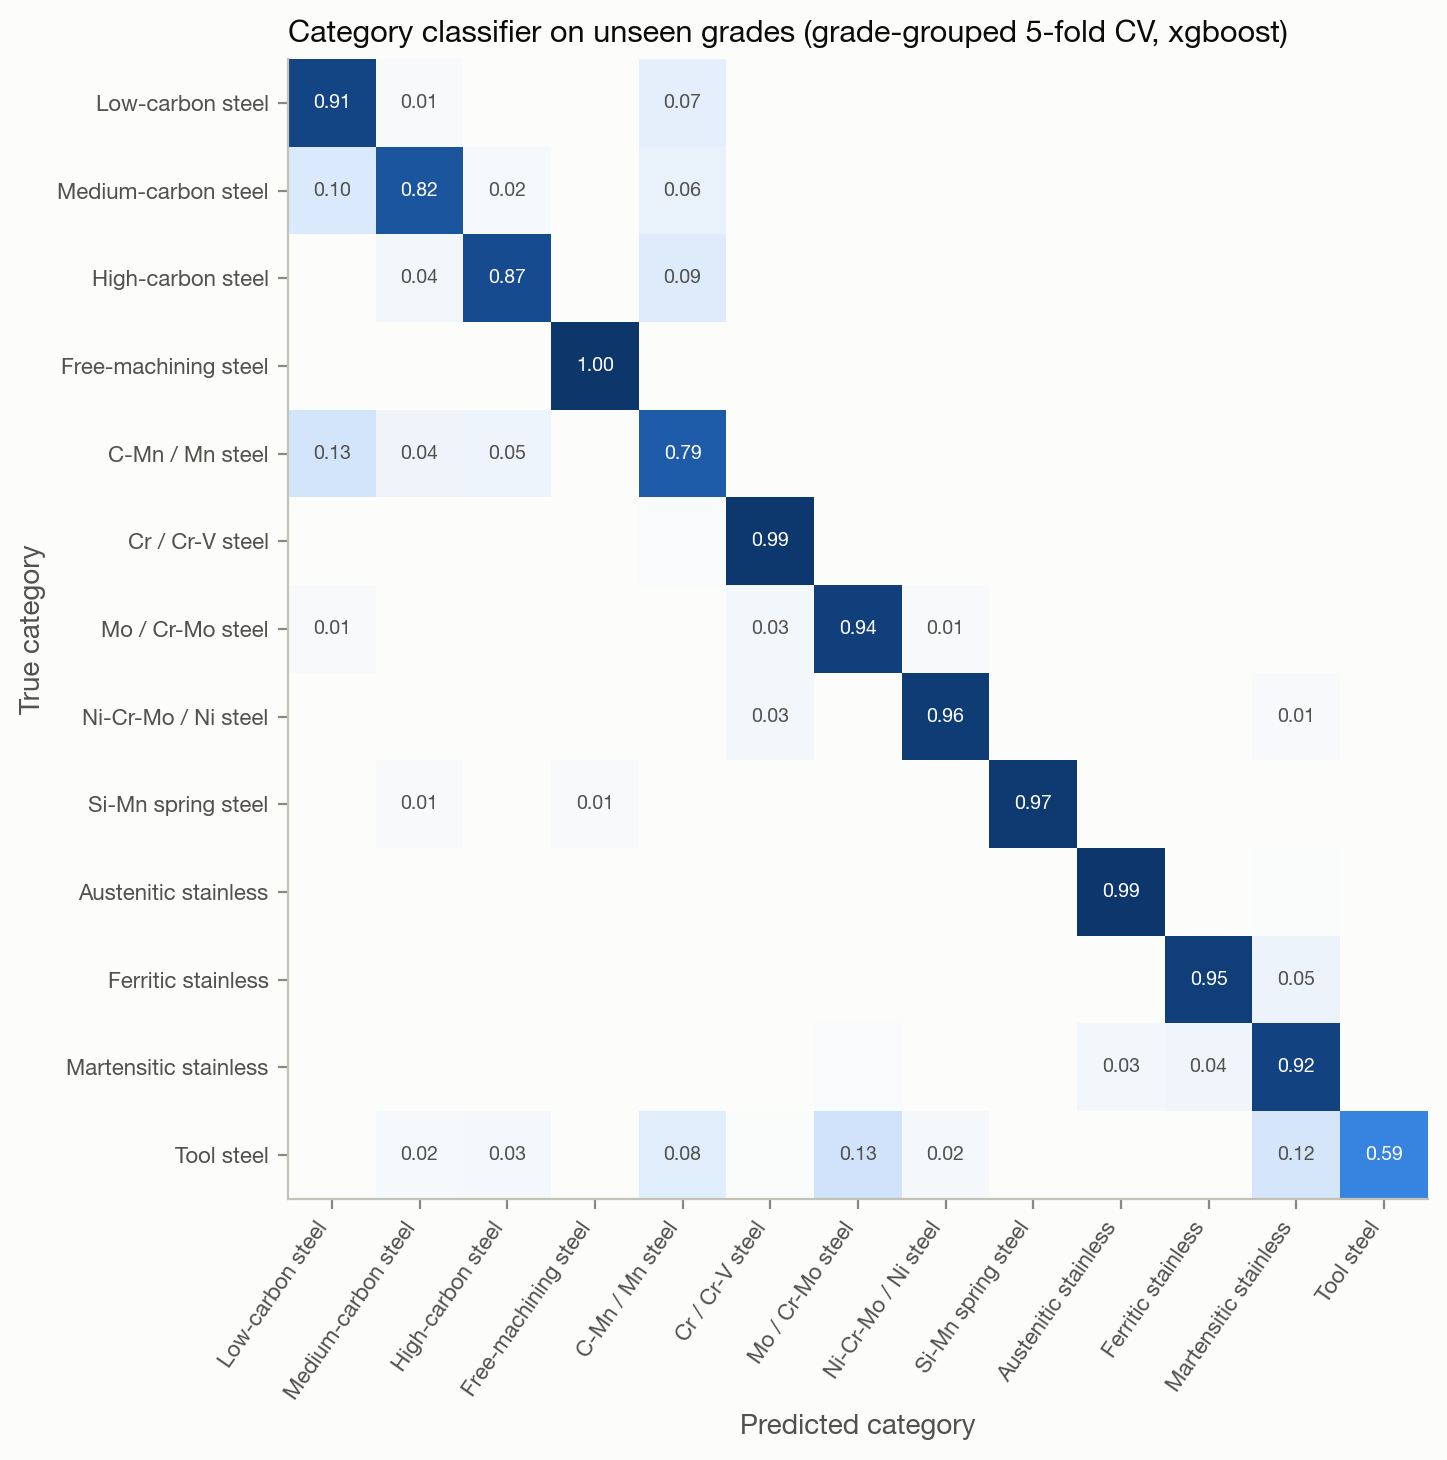

In [6]:
fig("fig03_category_confusion", 800)

## Which elements decide a category?
SHAP attributions agree with metallurgy: carbon separates low/medium/high-carbon steels, sulphur marks
free-machining steels, chromium the Cr and stainless families, nickel the Ni-bearing and austenitic grades,
silicon the Si-Mn spring steels.

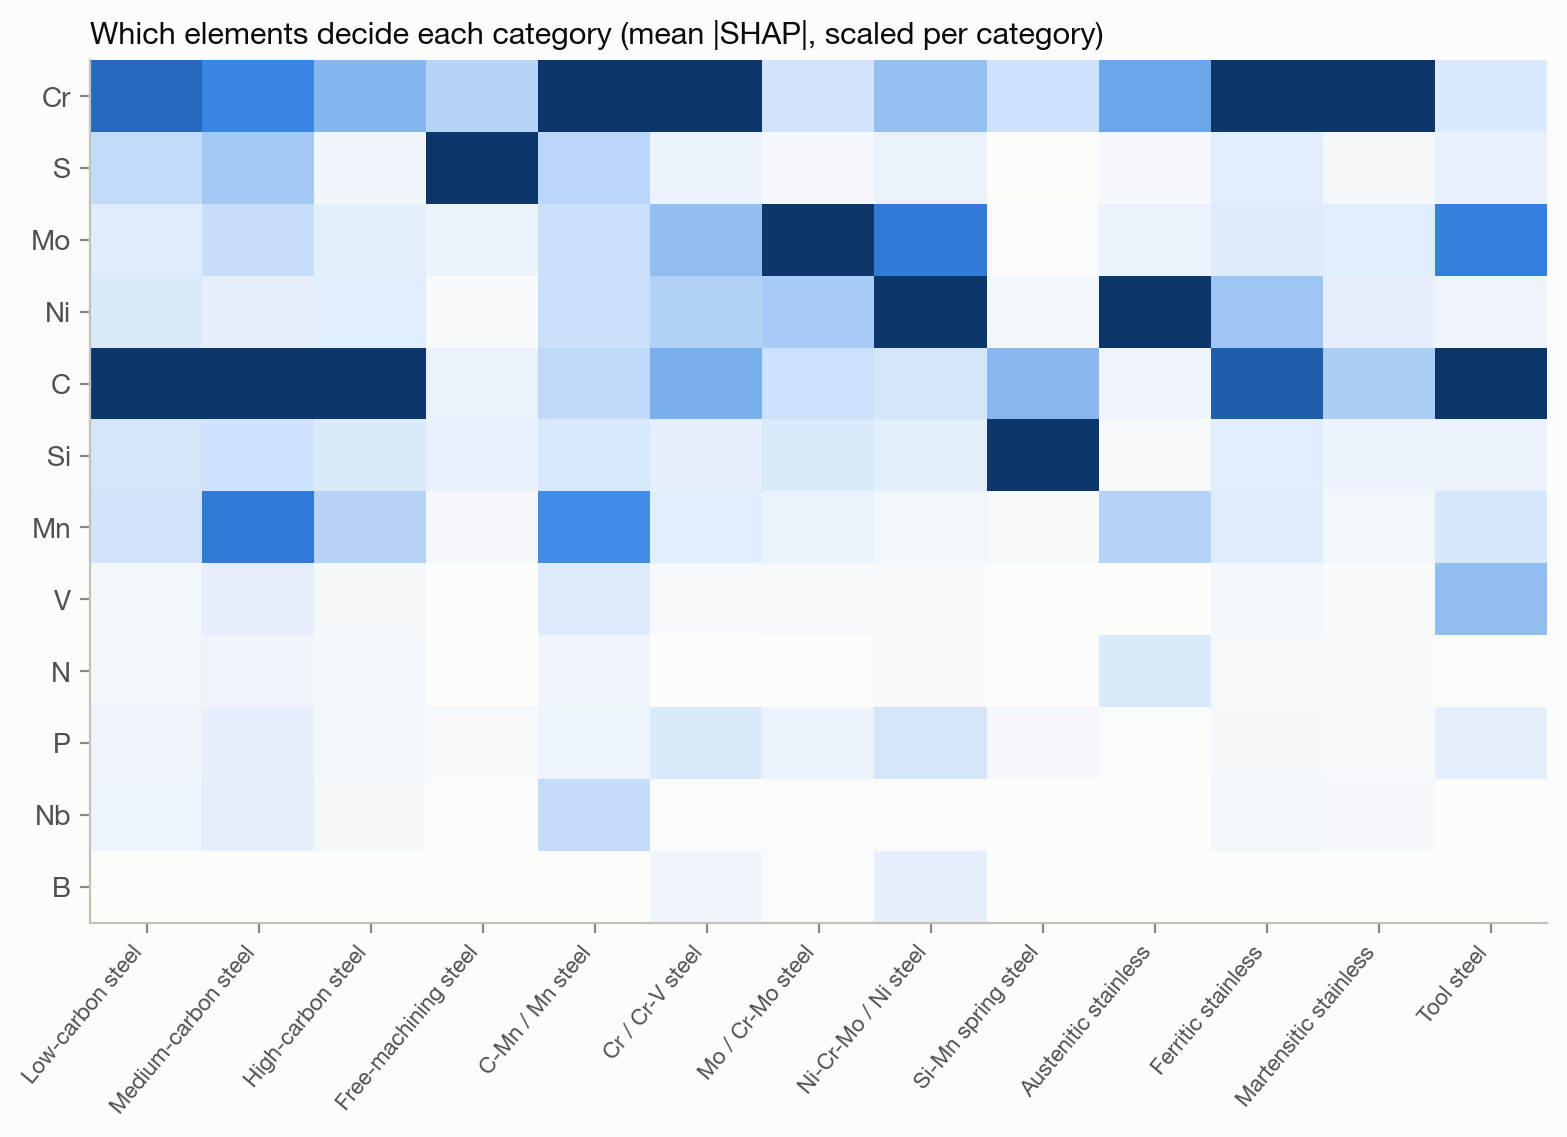

In [7]:
fig("fig04_category_shap", 900)

## Unsupervised view and open-set check
An unsupervised clustering of the catalogue recovers the families only partly (ARI below), which is why a
supervised model is needed. The novelty score rejects compositions unlike any known grade: all maraging
steels of the project's earlier dataset are flagged as *unknown*, so the cooling-route models refuse them.

In [8]:
pd.read_csv(R / "s02_unsupervised_agreement.csv")

,ARI,NMI
0,0.302,0.514


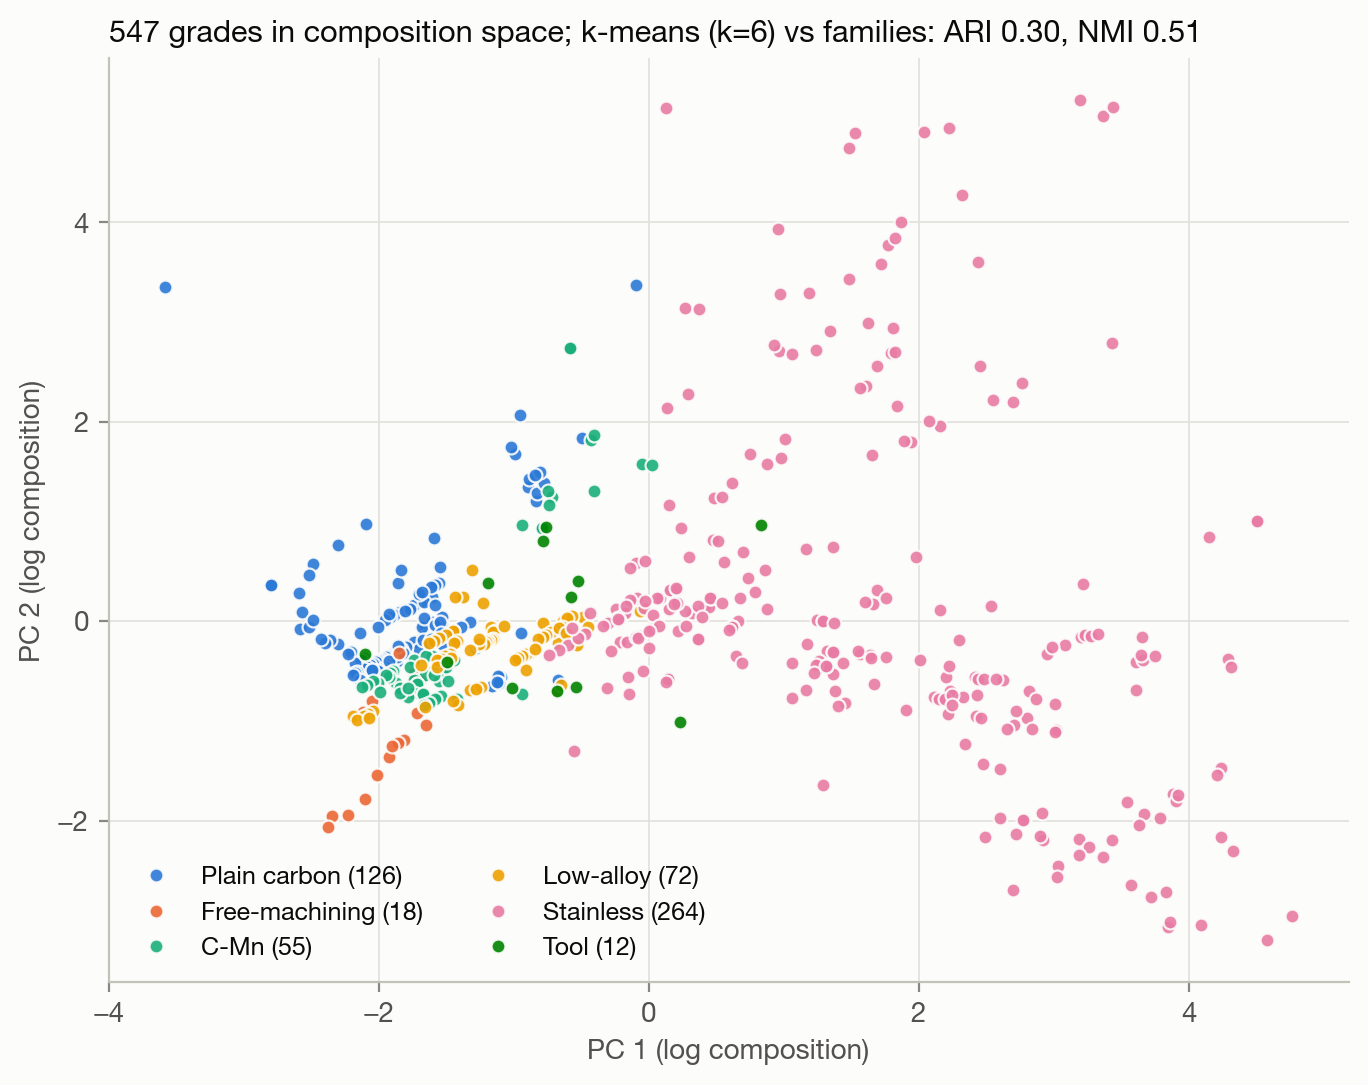

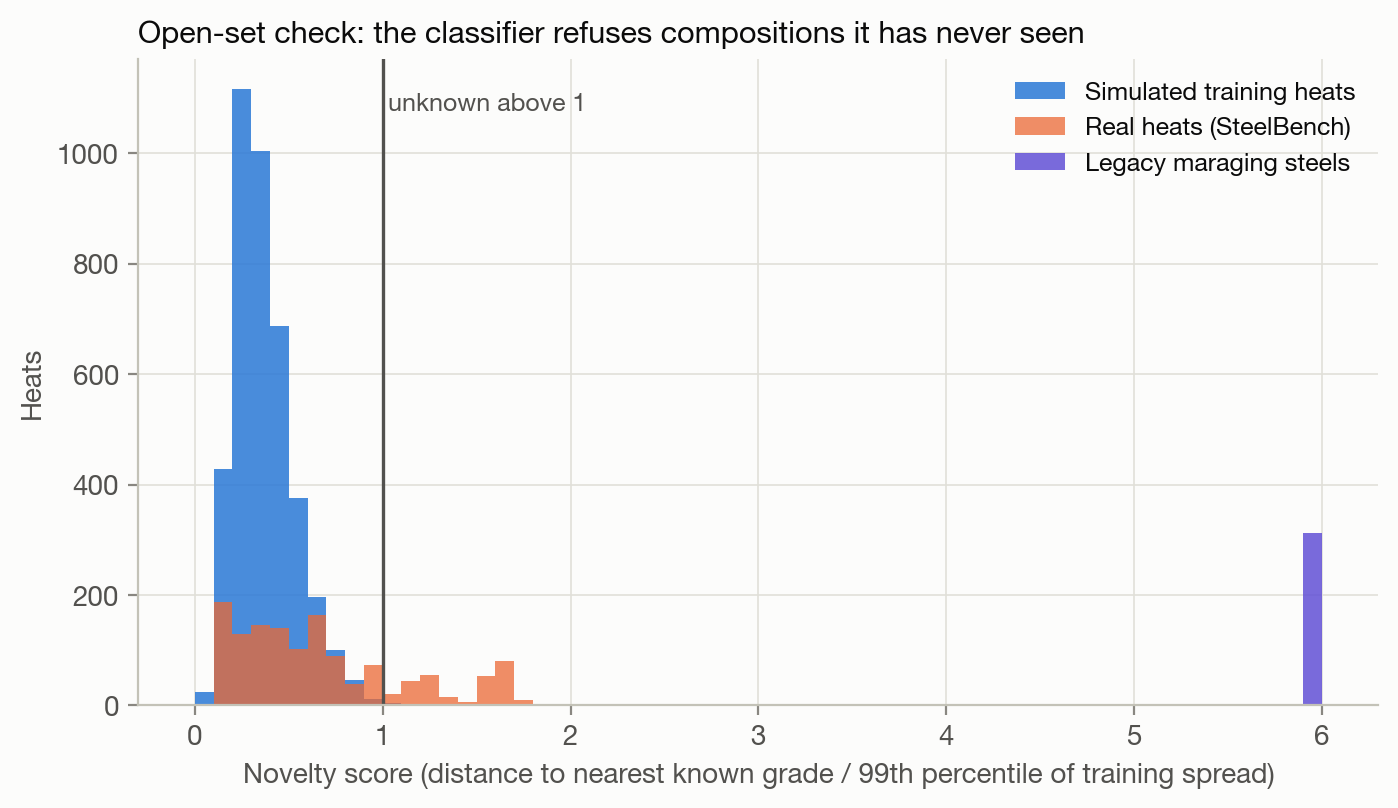

In [9]:
fig("fig05_catalog_embedding", 750); fig("fig06_category_novelty", 800)